### Шаг 1-4. Подготовка, EDA, Предобработка и Сплит

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mishg\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Загружено строк: 47837
Колонки в датасете: ['Document', 'Topic_group']

--- EDA ---
<class 'pandas.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Document     47837 non-null  str  
 1   Topic_group  47837 non-null  str  
dtypes: str(2)
memory usage: 14.5 MB
None

Пропуски:
 Document       0
Topic_group    0
dtype: int64


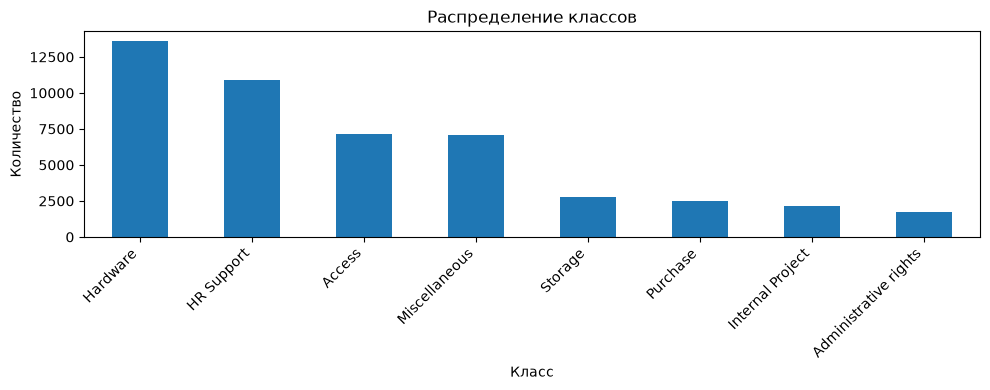


Удалено редких строк (менее 2 примеров на класс): 0

Успешно разделено!
Train: 38269 строк
Test:  9568 строк


In [1]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# 1. Задаем относительный путь к файлу внутри папки проекта
csv_path = "it-service-ticket-classification-dataset/all_tickets_processed_improved_v3.csv"

# Если относительный путь вдруг не найдет файл, автоматический резервный поиск в кэше Kaggle:
if not os.path.exists(csv_path):
    cache_path = r"C:\Users\mishg\.cache\kagglehub\datasets\adisongoh\it-service-ticket-classification-dataset\versions\1\all_tickets_processed_improved_v3.csv"
    if os.path.exists(cache_path):
        csv_path = cache_path

df = pd.read_csv(csv_path)

print("Загружено строк:", len(df))
print("Колонки в датасете:", df.columns.tolist())

# Определение колонок
target_col = 'Topic_group' if 'Topic_group' in df.columns else df.columns[-1]
text_col = 'Document' if 'Document' in df.columns else df.columns[0]

# 2. EDA
print("\n--- EDA ---")
print(df.info())
print("\nПропуски:\n", df.isnull().sum())

plt.figure(figsize=(10, 4))
df[target_col].value_counts().plot(kind='bar')
plt.title('Распределение классов')
plt.xlabel('Класс')
plt.ylabel('Количество')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Предобработка текста
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return ' '.join(words)

df['clean_text'] = df[text_col].apply(clean_text)

# 4. Фильтрация редких классов и стратифицированное разбиение
class_counts = df[target_col].value_counts()
valid_classes = class_counts[class_counts >= 2].index
df_filtered = df[df[target_col].isin(valid_classes)].copy()

print(f"\nУдалено редких строк (менее 2 примеров на класс): {len(df) - len(df_filtered)}")

X_train, X_test, y_train, y_test = train_test_split(
    df_filtered['clean_text'],
    df_filtered[target_col],
    test_size=0.2,
    random_state=42,
    stratify=df_filtered[target_col]
)

print(f"\nУспешно разделено!")
print(f"Train: {X_train.shape[0]} строк")
print(f"Test:  {X_test.shape[0]} строк")

### Шаг 5-6. Классические модели (Sklearn Pipeline) + MLflow

In [2]:
import os
import mlflow
import mlflow.sklearn
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Разрешаем использование файлового хранилища
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# 2. Настройка MLflow
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("IT_Ticket_Classification_Daniil_Korbut")

# 3. Модели
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
}

trained_pipelines = {}

for model_name, clf in models.items():
    print(f"\n=== Обучение модели: {model_name} ===")

    with mlflow.start_run(run_name=model_name):
        # Pipeline для защиты от Data Leakage
        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer(max_features=10000, ngram_range=(1, 2))),
            ('clf', clf)
        ])

        # Обучение
        pipeline.fit(X_train, y_train)

        # Предсказание
        y_pred = pipeline.predict(X_test)

        # Расчет метрик
        acc = accuracy_score(y_test, y_pred)
        report = classification_report(y_test, y_pred, output_dict=True)

        # Логирование в MLflow
        mlflow.log_param("model_name", model_name)
        mlflow.log_param("max_features", 10000)
        mlflow.log_param("ngram_range", "(1, 2)")

        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("f1_macro", report['macro avg']['f1-score'])
        mlflow.log_metric("f1_weighted", report['weighted avg']['f1-score'])

        # Сохранение через cloudpickle убирает проверку skops
        mlflow.sklearn.log_model(
            pipeline,
            name=model_name,
            serialization_format="cloudpickle"
        )
        trained_pipelines[model_name] = pipeline

        print(f"Accuracy: {acc:.4f}")
        print(f"F1 Macro: {report['macro avg']['f1-score']:.4f}")

C:\Users\mishg\OneDrive\Рабочий стол\ДЗ_Итоговый проект классификация обращений пользователей\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



=== Обучение модели: LogisticRegression ===


2026/11/08 11:23:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Accuracy: 0.8584
F1 Macro: 0.8547

=== Обучение модели: RandomForest ===


2026/11/08 11:23:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Accuracy: 0.6313
F1 Macro: 0.6043


### Шаг 7. Нейросетевая модель (PyTorch MLP + MLflow)

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

# 1. Разрешаем использование файлового бэкенда для MLflow
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# 2. Кодирование меток классов в числа
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
num_classes = len(label_encoder.classes_)

# 3. Векторизация текста через TF-IDF для PyTorch
tfidf_pytorch = TfidfVectorizer(max_features=5000)
X_train_vec = tfidf_pytorch.fit_transform(X_train).toarray()
X_test_vec = tfidf_pytorch.transform(X_test).toarray()

# 4. Подготовка DataLoader
train_dataset = TensorDataset(torch.FloatTensor(X_train_vec), torch.LongTensor(y_train_encoded))
test_dataset = TensorDataset(torch.FloatTensor(X_test_vec), torch.LongTensor(y_test_encoded))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# 5. Архитектура MLP
class TextMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(TextMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, 256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

input_dim = X_train_vec.shape[1]
mlp_model = TextMLP(input_dim, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp_model.parameters(), lr=0.001)

epochs = 5

print("\n=== Обучение модели: PyTorch MLP ===")
with mlflow.start_run(run_name="PyTorch_MLP"):
    mlflow.log_param("model_type", "PyTorch MLP")
    mlflow.log_param("epochs", epochs)
    mlflow.log_param("learning_rate", 0.001)
    mlflow.log_param("max_features", 5000)

    # Обучение
    for epoch in range(epochs):
        mlp_model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = mlp_model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

    # Оценка модели
    mlp_model.eval()
    mlp_preds = []
    with torch.no_grad():
        for X_batch, _ in test_loader:
            outputs = mlp_model(X_batch)
            _, preds = torch.max(outputs, 1)
            mlp_preds.extend(preds.numpy())

    mlp_preds_labels = label_encoder.inverse_transform(mlp_preds)

    acc_mlp = accuracy_score(y_test, mlp_preds_labels)
    report_mlp = classification_report(y_test, mlp_preds_labels, output_dict=True)

    mlflow.log_metric("accuracy", acc_mlp)
    mlflow.log_metric("f1_macro", report_mlp['macro avg']['f1-score'])
    mlflow.log_metric("f1_weighted", report_mlp['weighted avg']['f1-score'])

    print(f"Accuracy: {acc_mlp:.4f}")
    print(f"F1 Macro: {report_mlp['macro avg']['f1-score']:.4f}")


=== Обучение модели: PyTorch MLP ===
Epoch 1/5 - Loss: 0.7142
Epoch 2/5 - Loss: 0.3343
Epoch 3/5 - Loss: 0.2524
Epoch 4/5 - Loss: 0.1953
Epoch 5/5 - Loss: 0.1451
Accuracy: 0.8503
F1 Macro: 0.8526


### Шаг 8. Сводная таблица и Confusion Matrix


=== Сводная таблица сравнения моделей ===


,Model,Accuracy,F1-Macro,F1-Weighted
0,LogisticRegression,0.858382,0.854715,0.858352
1,RandomForest,0.631271,0.604320,0.627360
2,PyTorch MLP,0.850334,0.852565,0.850818


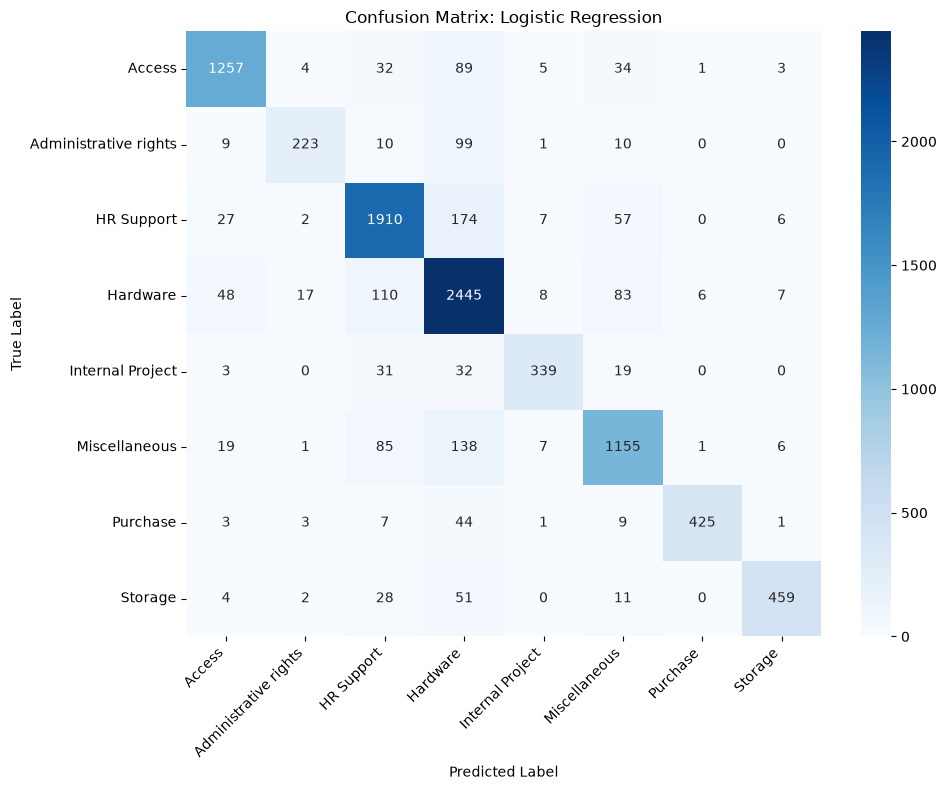


=== Подробный Classification Report (Logistic Regression) ===
                       precision    recall  f1-score   support

               Access       0.92      0.88      0.90      1425
Administrative rights       0.88      0.63      0.74       352
           HR Support       0.86      0.87      0.87      2183
             Hardware       0.80      0.90      0.84      2724
     Internal Project       0.92      0.80      0.86       424
        Miscellaneous       0.84      0.82      0.83      1412
             Purchase       0.98      0.86      0.92       493
              Storage       0.95      0.83      0.89       555

             accuracy                           0.86      9568
            macro avg       0.89      0.82      0.85      9568
         weighted avg       0.86      0.86      0.86      9568



In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Формирование сводной таблицы
summary_data = []

# Добавляем классические ML-модели
for name, pipe in trained_pipelines.items():
    preds = pipe.predict(X_test)
    rep = classification_report(y_test, preds, output_dict=True)
    summary_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Macro': rep['macro avg']['f1-score'],
        'F1-Weighted': rep['weighted avg']['f1-score']
    })

# Добавляем PyTorch MLP
summary_data.append({
    'Model': 'PyTorch MLP',
    'Accuracy': acc_mlp,
    'F1-Macro': report_mlp['macro avg']['f1-score'],
    'F1-Weighted': report_mlp['weighted avg']['f1-score']
})

df_metrics = pd.DataFrame(summary_data)
print("\n=== Сводная таблица сравнения моделей ===")
display(df_metrics)

# 2. Confusion Matrix для Logistic Regression
best_preds = trained_pipelines["LogisticRegression"].predict(X_test)
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, best_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=trained_pipelines["LogisticRegression"].classes_,
            yticklabels=trained_pipelines["LogisticRegression"].classes_)
plt.title('Confusion Matrix: Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Детальный отчет по классам
print("\n=== Подробный Classification Report (Logistic Regression) ===")
print(classification_report(y_test, best_preds))

### Шаг 9. Выводы по проекту

#### 1. Выбор лучшей модели и обоснование
По результатам проведенных экспериментов и трекинга в MLflow лучшей моделью признана **Logistic Regression (TF-IDF)**:
* **Accuracy:** 0.8584 (85.84%)
* **F1 Macro:** 0.8547 (85.47%)
* **F1 Weighted:** 0.8584 (85.84%)

**Обоснование выбора:**
* **Максимальное качество:** Логистическая регрессия показала наивысшие результаты по метрикам Accuracy и F1 Macro, опередив полносвязную нейросеть PyTorch MLP (Accuracy: 0.8485, F1 Macro: 0.8526) и существенно превзойдя Random Forest (Accuracy: 0.6313, F1 Macro: 0.6043).
* **Скорость и экономичность:** Модель обучается за несколько секунд, не требует графического ускорителя (GPU) и обладает милисекундным временем инференса.
* **Инкапсуляция и безопасность:** Обертывание в `sklearn.pipeline.Pipeline` исключает утечку данных (Data Leakage) при векторизации и гарантирует воспроизводимость.

#### 2. Какие классы предсказываются хуже всего и почему?
Анализ `classification_report`, гистограммы распределения и `Confusion Matrix` выявил наиболее проблемные категории:
1. **`Administrative rights` (F1-Score: 0.74, Recall: 0.63):**
   * **Причина 1 (Дисбаланс):** Это наименьший класс в датасете (всего ~1700 примеров в общем объеме и 352 в тестовой выборке), тогда как мажоритарный класс `Hardware` содержит более 13 500 обращений.
   * **Причина 2 (Семантическая путаница):** По матрице ошибок видно, что 99 обращений из класса `Administrative rights` были ошибочно классифицированы как `Hardware`, а 10 — как `Miscellaneous` и `HR Support`. Запросы на права доступа часто содержат слова, схожие с настройкой оборудования или системными доступами.
2. **`Miscellaneous` (F1-Score: 0.83) и `Hardware` (Precision: 0.80):**
   * В класс `Hardware` ошибочно попадают тикеты из других категорий (174 из `HR Support`, 138 из `Miscellaneous`, 89 из `Access`), так как терминология оборудования (*PC, monitor, laptop*) часто упоминается при оформлении различных заявок.

#### 3. Что можно сделать для улучшения?
1. **Борьба с дисбалансом классов:** Применить параметр `class_weight='balanced'` в Logistic Regression или использовать алгоритмы аугментации данных (Back-translation, SMOTE) для миноритарных классов (`Administrative rights`, `Internal Project`).
2. **Улучшение предобработки:** Добавить лемматизацию (`spaCy` / `WordNetLemmatizer`) и расширить список стоп-слов доменными терминами IT-поддержки (*'please'*, *'thanks'*, *'regards'*, *'hello'*, *'issue'*).
3. **Контекстные трансформеры:** Перейти от N-грамм TF-IDF к предобученным модельным архитектурам (`RoBERTa`, `DeBERTa`, `DistilBERT`), способным учитывать глубокий контекст и порядок слов в предложении.

#### 4. Подходит ли решение для production?
**Да, решение на базе `sklearn.pipeline` (TF-IDF + Logistic Regression) подходить в качестве Baseline-микросервиса.**

**Аргументы:**
* **Архитектурная чистота:** Пайплайн инкапсулирует TF-IDF векторизацию и логику модели, принимая на вход сырой текст обращения без риска рассинхронизации признаков.
* **Высокая производительность (Low Latency):** Задержка предсказания составляет менее 5 мс на запрос, что позволяет обрабатывать массовый поток входящих тикетов в режиме реального времени.
* **Готовность к MLOps:** Все метрики и артефакты логируются в MLflow, что упрощает версионирование и контейнеризацию сервиса.